<a href="https://colab.research.google.com/github/ust-buan-640/buan-640-notebooks/blob/main/notebooks/m11-3-computing-the-line.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simple linear regression in Python

This notebook fits the least squares line for all 89 North Ames homes in Python: load the data, look at it, fit the model, and read the coefficients.

*Data: Ames housing data (De Cock, 2011, Journal of Statistics Education), single-family homes in the North Ames neighborhood sold under normal conditions in 2007. `area` is the above-ground living area in square feet, and `price` is the sale price in dollars.*

## Libraries

`pandas` reads and holds the data, `matplotlib` draws the plots, and `statsmodels` fits the regression.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols

## Load the data

In [2]:
homes = pd.read_csv("https://raw.githubusercontent.com/ust-buan-640/buan-640-notebooks/main/data/north_ames_2007.csv")
homes.head()

,price,area,year_built,month_sold,bedrooms,full_baths,lot_area
0,167300,1587,1971,3,3,2,10667
1,167000,1277,1970,4,2,1,10628
2,244000,2223,1973,2,3,2,13651
3,268000,2217,1970,10,4,2,15865
4,139000,1109,1971,12,3,1,10500


Each row is one home. We need two columns: `area`, the explanatory variable, and `price`, the response.

In [3]:
homes[["area", "price"]].describe()

,area,price
count,89.000000,89.000000
mean,1223.101124,143575.280899
std,335.669719,27909.566953
min,858.000000,99000.000000
25%,948.000000,126500.000000
50%,1109.000000,139400.000000
75%,1411.000000,156000.000000
max,2223.000000,268000.000000


## Look at the data

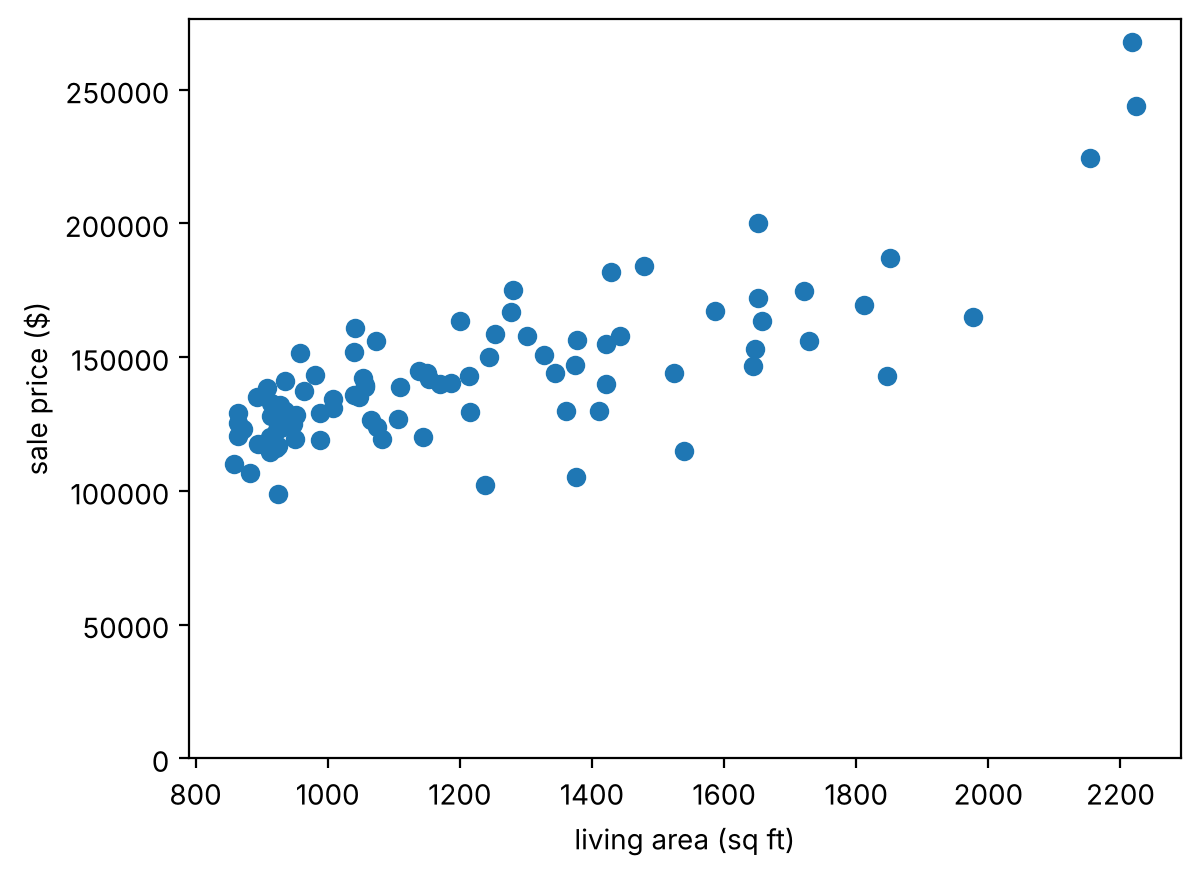

In [4]:
plt.scatter(homes["area"], homes["price"])
plt.xlabel("living area (sq ft)")
plt.ylabel("sale price ($)")
plt.ylim(bottom=0)
plt.show()

## Fit the model

The formula `"price ~ area"` reads "price explained by area": the response goes on the left of `~`, the explanatory variable on the right. `statsmodels` adds the intercept by itself. `.fit()` computes the least squares line.

In [5]:
model = ols("price ~ area", data=homes).fit()

## The coefficients

`Intercept` is $b_0$ and `area` is $b_1$.

In [6]:
model.params

Intercept    65364.147932
area            63.944944
dtype: float64

## The full output

`summary()` prints everything at once. For now, find the `coef` column: it holds the same two numbers. The other columns, R-squared at the top, and the notes at the bottom come later.

In [7]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.591
Model:                            OLS   Adj. R-squared:                  0.587
Method:                 Least Squares   F-statistic:                     126.0
Date:                Fri, 27 Nov 2026   Prob (F-statistic):           1.35e-18
Time:                        20:42:04   Log-Likelihood:                -997.02
No. Observations:                  89   AIC:                             1998.
Df Residuals:                      87   BIC:                             2003.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   6.536e+04   7223.617      9.049      0.000     5.1e+04    7.97e+04
area          63.9449      5.698     11.223      0.000      52.620      75.270
==============================================================================
Omnibus:                        5.668   Durbin-Watson:                   1.550
Prob(Omnibus):                  0.059   Jarque-Bera (JB):                8.532
Skew:                          -0.085   Prob(JB):                       0.0140
Kurtosis:                       4.507   Cond. No.                     4.82e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 4.82e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## The line on the plot

`model.fittedvalues` holds the predicted price $\hat{y}$ for every home in the data.

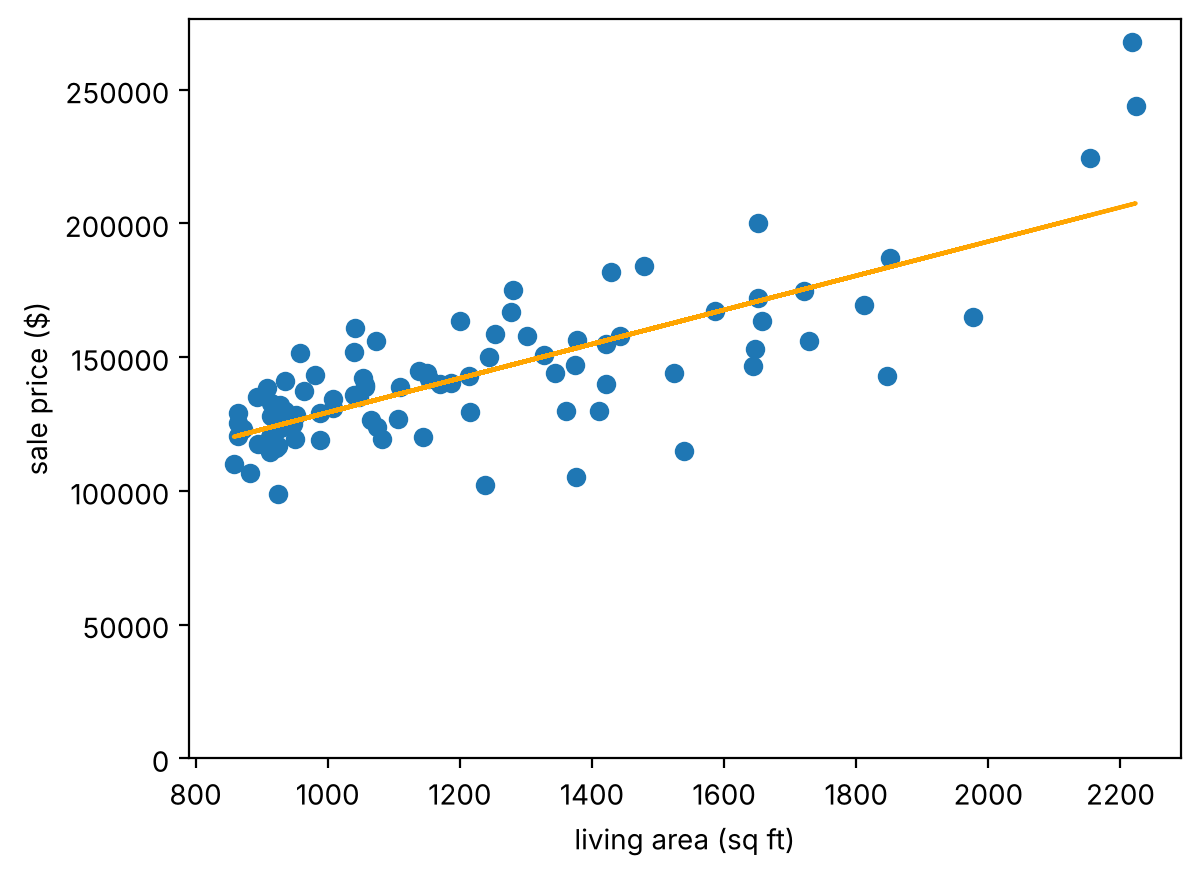

In [8]:
plt.scatter(homes["area"], homes["price"])
plt.plot(homes["area"], model.fittedvalues, color="orange")
plt.xlabel("living area (sq ft)")
plt.ylabel("sale price ($)")
plt.ylim(bottom=0)
plt.show()

## Predicted values and residuals

`model.resid` holds the residuals, $e = y - \hat{y}$.

In [9]:
homes["predicted"] = model.fittedvalues
homes["residual"] = model.resid
homes[["area", "price", "predicted", "residual"]].head()

,area,price,predicted,residual
0,1587,167300,166844.774206,455.225794
1,1277,167000,147021.841537,19978.158463
2,2223,244000,207513.758648,36486.241352
3,2217,268000,207130.088984,60869.911016
4,1109,139000,136279.090930,2720.909070


## Predicting new homes

`predict()` needs a table with a column named exactly like the explanatory variable.

In [10]:
new_homes = pd.DataFrame({"area": [1000, 1500, 2000]})
model.predict(new_homes)

0    129309.092024
1    161281.564070
2    193254.036116
dtype: float64